In [7]:
import numpy as np
import torch
import torch.fft as fft
import torchoptics
from torch.nn import Parameter
from torchoptics import Field, System, visualize_tensor
from torchoptics.elements import PhaseModulator
from torchoptics.profiles import gaussian, square, circle
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"

### Setup variables

C:\Users\PC\AppData\Local\Temp\ipykernel_4244\2473856110.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[0].imshow(np.abs(source_profile))
C:\Users\PC\AppData\Local\Temp\ipykernel_4244\2473856110.py:23: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axs[1].imshow(np.abs(target_profile))


Text(0.5, 1.0, 'Target profile')

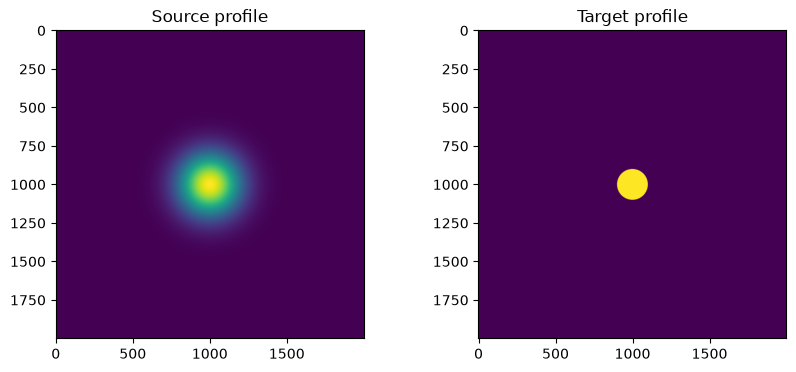

In [15]:
# Pixel size must be 2.5 µm to match the article's 5x5 mm total dimension
dx = 2.5e-6
lam = 532e-9
torchoptics.set_default_spacing(dx)
torchoptics.set_default_wavelength(lam)

shape = 2000
waist_radius = 0.5e-3
target_pos = 25e-3

pixels = 80
square_side = pixels * dx

# Generate raw profile tensors for explicit FFT propagation
source_profile = gaussian(shape, waist_radius=waist_radius).to(device)
#target_profile = square(shape, side=square_side).to(device)
target_profile = circle(shape, radius = waist_radius/2).to(device)


fig, axs = plt.subplots(1,2,figsize = (10,4))
axs[0].imshow(np.abs(source_profile))
axs[0].set_title("Source profile")
axs[1].imshow(np.abs(target_profile))
axs[1].set_title("Target profile")

### Algorithm preparation

In [16]:
# Normalize target amplitude based on total source irradiance (per the algorithm)
total_source_irradiance = torch.sum(torch.abs(source_profile) ** 2)
total_target_irradiance = torch.sum(torch.abs(target_profile) ** 2)
scaling_factor = torch.sqrt(total_source_irradiance / total_target_irradiance)
A_tgt = target_profile * scaling_factor

# Initialize Random Binary Phase (0 or pi)
torch.manual_seed(0)
phi = torch.randint(0, 2, (shape, shape), device=device, dtype=torch.float32) * torch.pi

# --- Pre-calculate Angular Spectrum Transfer Functions ---
fx = fft.fftfreq(shape, d=dx, device=device)
fy = fft.fftfreq(shape, d=dx, device=device)
FX, FY = torch.meshgrid(fx, fy, indexing='ij')

term = 1 - (lam * FX) ** 2 - (lam * FY) ** 2
mask = term >= 0  # Filter out evanescent waves
phase_term = 2 * torch.pi * target_pos / lam * torch.sqrt(term * mask)

H_fw = torch.exp(1j * phase_term) * mask  # Forward propagation
H_bw = torch.exp(1j * (-phase_term)) * mask  # Backward propagation

efficiencies = []


### Optimization loop

In [17]:
for iteration in range(100):
    # 1. Modulate incident wave
    E1 = source_profile * torch.exp(1j * phi)

    # 2. Forward propagate to target plane
    E2 = fft.ifft2(fft.fft2(E1) * H_fw)

    # Calculate Conversion Efficiency (Monitoring)
    target_mask = (target_profile > 0).float()
    power_in_target = torch.sum((torch.abs(E2) ** 2) * target_mask)
    eff = (power_in_target / total_source_irradiance).item()
    efficiencies.append(eff)

    # Termination criterion
    if iteration > 0 and abs(eff - efficiencies[-2]) <= 1e-3:
        print(f"Converged at iteration {iteration}. Efficiency: {eff:.4f}")
        break

    # 3. Modify Target: Replace amplitude, maintain phase
    E20 = A_tgt * torch.exp(1j * torch.angle(E2))

    # 4. Backward propagate to DOE plane
    E10 = fft.ifft2(fft.fft2(E20) * H_bw)

    # 5. Calculate Sensitivity Metric
    ds = torch.real(E1 * E10)

    # 6. Phase Update Rule (Toggle where ds < 0)
    toggle_mask = ds < 0
    phi = torch.where(toggle_mask, torch.pi - phi, phi)

    if iteration % 10 == 0:
        print(f"Iteration {iteration} | Efficiency: {eff:.4f}")

Iteration 0 | Efficiency: 0.0068
Iteration 10 | Efficiency: 0.5244
Iteration 20 | Efficiency: 0.5428
Converged at iteration 23. Efficiency: 0.5465


### Process results in simulated system

Text(0.5, 1.0, 'Output field magnitude')

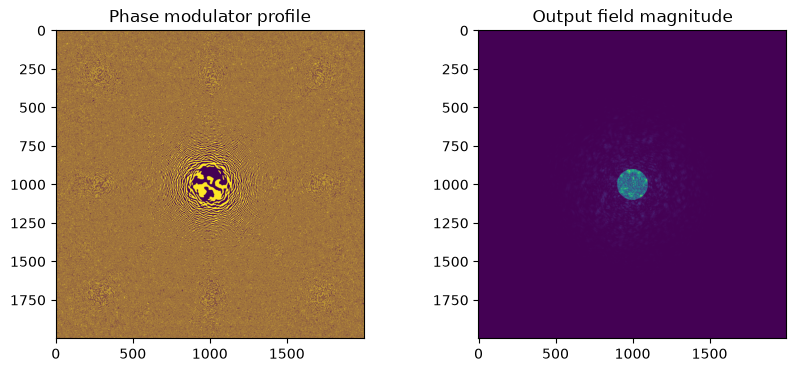

In [23]:
input_field = Field(source_profile, z=0).to(device)

system = System(
    # Detach from any computation history, load directly as final phase
    PhaseModulator(Parameter(phi.detach()), z=0),
).to(device)

output_field = system.measure_at_z(input_field, target_pos)

fig, ax = plt.subplots(1,2,figsize = (10,4))
ax[0].imshow(phi)
ax[0].set_title("Phase modulator profile")

ax[1].imshow(output_field.intensity().detach().numpy())
ax[1].set_title("Output field magnitude")